# POST-PHASE-13 H2-B-B2 — Downstream Regional Segmentation Analysis

## 1. Governance / Branch Identity

READ-ONLY on rerun. No training, no localizer inference, no hidden segmentation inference —
this notebook only reads on-disk artifacts produced by the H2B-B2 execution.

Branch: Phase 13 `REVISE_LOCALIZER` → H1 `CLOSED__PARTIAL_MITIGATION_INSUFFICIENT` →
H2A `CLOSED__SELECTION_REDESIGN_PARTIAL` → **H2B objective-only redesign**.

Run id: `post_phase13_h2b_downstream_best_native_policy`.


In [1]:

import hashlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.figsize"] = (10, 5)

ROOT = Path(r"D:\Softfors\jup")
AUDITS = ROOT / "reports" / "audits"
TABLES = ROOT / "reports" / "tables"
EID = ("post_phase13_h2b_kub_localizer_r512_h128_sigmaeq075_"
       "softtargetfocalgamma2_deploymentbalance_seed42_clean_v3")

def sha(p):
    p = Path(p)
    if not p.is_absolute():
        p = ROOT / p
    return hashlib.sha256(p.read_bytes()).hexdigest()

integ = json.loads((AUDITS / "post_phase13_h2b_b2_downstream_integrity.json").read_text("utf-8"))
case = pd.read_csv(TABLES / "post_phase13_h2b_downstream_case_model_metrics.csv")
comp = pd.read_csv(TABLES / "post_phase13_h2b_downstream_component_model_metrics.csv")
summary = pd.read_csv(TABLES / "post_phase13_h2b_downstream_model_summary.csv")
cross = pd.read_csv(TABLES / "post_phase13_h2b_downstream_cross_architecture_summary.csv")
link = pd.read_csv(TABLES / "post_phase13_h2b_localizer_to_downstream_comparison.csv")
print("Environment OK | case rows:", len(case), "| component rows:", len(comp))


Environment OK | case rows: 412 | component rows: 608


## 2. H2B Objective-Only Rationale

H2A returned `H2A_SELECTION_REDESIGN_PARTIAL`: checkpoint selection improved the localizer but
left a substantial off-target proposal burden. H2B tests whether a **soft-target objective**
(`SoftTargetFocalBCE`, gamma=2.0) improves heatmap discrimination with everything else frozen.
This notebook evaluates whether that objective-level change translates into downstream regional
segmentation behaviour.


## 3. B1 Best-Checkpoint Identity

In [2]:

te = json.loads((AUDITS / "post_phase13_h2b_b1_training_evaluation.json").read_text("utf-8"))
print("experiment_id:", te["experiment_id"])
print("best epoch:", te["termination"]["best_epoch"], "| completed epochs:", te["termination"]["completed_epochs"])
print("termination:", te["termination"]["reason"])
print("best.pt SHA:", te["hashes"]["best_pt_sha"])
print("history SHA:", te["hashes"]["history_sha"])
print("loss:", te["loss"]["class"], "| gamma:", te["loss"]["gamma"])


experiment_id: post_phase13_h2b_kub_localizer_r512_h128_sigmaeq075_softtargetfocalgamma2_deploymentbalance_seed42_clean_v3
best epoch: 31 | completed epochs: 46
termination: EARLY_STOPPING_PATIENCE
best.pt SHA: a9147ad7d1835a6e4ef8d66cc04c063db85b2f9a65585a4a34ae2acfef05f028
history SHA: ce8512ffbbcd8912d6cee2d29e5f2d6b9f210efb66e260847bbc2379bb5325a6
loss: src.losses.soft_target_focal_bce.SoftTargetFocalBCE | gamma: 2.0


## 4. B1 Interruption / Resume Provenance

In [3]:

h = pd.read_csv(ROOT / "experiments" / EID / "history.csv")
print("history rows:", len(h))
print("contiguous 1..N:", bool((h.epoch.diff().dropna() == 1).all()) and int(h.epoch.iloc[0]) == 1)
print("duplicate epochs:", int(h.epoch.duplicated().sum()))
print("logical_scientific_experiment_count:", te["counters"]["logical_training_experiments"])
print("execution_attempt_count:", te["counters"]["execution_attempt_count"])
print("note: first attempt was interrupted mid-epoch 44 and resumed with --resume (not a second experiment).")


history rows: 46
contiguous 1..N: True
duplicate epochs: 0
logical_scientific_experiment_count: 1
execution_attempt_count: 2
note: first attempt was interrupted mid-epoch 44 and resumed with --resume (not a second experiment).


## 5. B1 Selection Replay

In [4]:

rp = json.loads((AUDITS / "post_phase13_h2b_b1_selection_replay_verification.json").read_text("utf-8"))
print("status:", rp["status"], "| mismatches:", rp["mismatch_count"])
print("best epoch replayed/stored:", rp["replayed"]["best_epoch"], "/", rp["stored"]["best_epoch"])
print("max abs term diff:", rp["max_abs_term_diff"])
print("final bad epochs:", rp["replayed"]["final_bad_epochs"])


status: PASS | mismatches: 0
best epoch replayed/stored: 31 / 31
max abs term diff: 7.19910242530375e-17
final bad epochs: 15


## 6. Frozen 488-Proposal Identity

In [5]:

prop = pd.read_csv(TABLES / "post_phase13_h2b_best_checkpoint_proposals.csv")
pcase = pd.read_csv(TABLES / "post_phase13_h2b_best_checkpoint_case_proposals.csv")
pcomp = pd.read_csv(TABLES / "post_phase13_h2b_best_checkpoint_component_coverage.csv")
print("proposals:", len(prop), "| cases:", len(pcase), "| components:", len(pcomp))
print("proposal config: threshold=0.10 margin=0.20 top_k=5 NMS=0.30")
assert len(prop) == 488 and len(pcase) == 103 and len(pcomp) == 152
print("CONFIRMED: 488 frozen H2B proposals (authoritative downstream identity)")


proposals: 488 | cases: 103 | components: 152
proposal config: threshold=0.10 margin=0.20 top_k=5 NMS=0.30
CONFIRMED: 488 frozen H2B proposals (authoritative downstream identity)


## 7. H2B vs H2A Localizer Comparison

In [6]:

l2 = pd.read_csv(TABLES / "post_phase13_h2b_vs_h2a_localizer_comparison.csv")
print(l2.to_string(index=False))


                        quantity  phase13_best_epoch53  h2a_best_epoch83   h2b_best  delta_h2b_minus_h2a
            proposal_total_count            494.000000        457.000000 488.000000            31.000000
proposal_pixel_any_hit_precision              0.246964          0.275711   0.215164            -0.060547
 proposal_bbox_any_hit_precision              0.248988          0.273523   0.213115            -0.060408
                   tiny_recall90              0.680556          0.694444   0.611111            -0.083333
                overall_recall90              0.598684          0.638158   0.592105            -0.046053
                overall_recall50              0.789474          0.822368   0.697368            -0.125000
              any_overlap_recall              0.848684          0.875000   0.736842            -0.138158
                   mean_coverage              0.758402          0.787897   0.677809            -0.110088
        mean_proposal_union_area              0.004846 

## 8. Segmentation Checkpoint Bindings

In [7]:

for k, v in integ["segmentation_checkpoint_shas"].items():
    print(f"  {k:<18} {v}")


  unet               7b955ba86464a2fec2d569ecb6124de1fa9a4e66d0b5d58b267be9a280b4c2c0
  attention_unet     a49b19d66e43b57ed082ea6efc0ac10bccf444277abd3540dc68612bf30b88b3
  unetpp             ec7eb13f32e43af27eab7fc617bd1a2a8fcce1d6651a1b4a3653f3e4d1283269
  deeplabv3plus      f519027ba1a3a4d6212d83fecd4379f61f71bc05b0751924b9660da08d597dad


## 9. Global Cache Reproduction

In [8]:

print("manifest SHA:", integ["global_cache_manifest_sha"])
print("expected    : 76e1034d2bc7925260af33826fc19565b2d5ef786c612a7ad71f3bde46fb89a8")
print("global reproduction:", integ["global_reproduction"])


manifest SHA: 76e1034d2bc7925260af33826fc19565b2d5ef786c612a7ad71f3bde46fb89a8
expected    : 76e1034d2bc7925260af33826fc19565b2d5ef786c612a7ad71f3bde46fb89a8
global reproduction: PASS


## 10. Crop / Restore

Native valid region → zero-pad to full square → 512 bilinear → [0,1]. Restore: 512 regional
probability → full square bilinear (`align_corners=False`) → strip pad → native coordinates.
The frozen proposal margin is already baked into the proposal geometry — never applied twice.


In [9]:

print("Part1D helper SHA:", integ["part1d_helper_sha"])
print("expected          : 8cd7e39814a049a025f706c57ccea0b535a230908a177690d6289318234c6284")


Part1D helper SHA: 8cd7e39814a049a025f706c57ccea0b535a230908a177690d6289318234c6284
expected          : 8cd7e39814a049a025f706c57ccea0b535a230908a177690d6289318234c6284


## 11. Fusion

`U_H2B` = union of clipped H2B proposal rectangles. Regional overlap: **MAX among regional
predictions only**. Final: `P(x) = R(x)` inside `U_H2B`, `P(x) = G(x)` outside. **Never**
`max(G,R)`. Zero proposals → `P == G` exactly. Threshold 0.5 after native fusion.


In [10]:

print("regional crop evaluations:", integ["regional_crop_evaluations"], "/ 1952")
print("localizer forwards:", integ["localizer_forwards"])
print("proposal regeneration:", integ["proposal_regeneration"])
print("new global forwards:", integ["new_global_forwards"])


regional crop evaluations: 1952 / 1952
localizer forwards: 0
proposal regeneration: 0
new global forwards: 0


## 12. Downstream Model Summary

In [11]:

pd.set_option("display.max_columns", None); pd.set_option("display.width", 0)
print(summary.to_string(index=False))


         model   model_display  proposal_count  mean_proposals_per_image  mean_intervention_union_area  global_macro_dice  phase13_predicted_macro_dice  h2b_predicted_macro_dice  oracle_macro_dice  DELTA_H2B_GLOBAL_DICE  DELTA_H2B_PHASE13_DICE  h2a_predicted_macro_dice  h2a_predicted_macro_iou  h2a_predicted_macro_precision  h2a_predicted_macro_recall  mean_h2a_fp  mean_h2a_fn  DELTA_H2B_H2A_DICE  ORACLE_GAIN_FROM_GLOBAL  H2B_ORACLE_BENEFIT_RETENTION  H2B_ORACLE_GAP  global_macro_iou  phase13_predicted_macro_iou  h2b_predicted_macro_iou  oracle_macro_iou  global_macro_precision  phase13_predicted_macro_precision  h2b_predicted_macro_precision  oracle_macro_precision  global_macro_recall  phase13_predicted_macro_recall  h2b_predicted_macro_recall  oracle_macro_recall  mean_global_fp  mean_phase13_fp  mean_h2b_fp  mean_oracle_fp  mean_global_fn  mean_phase13_fn  mean_h2b_fn  mean_oracle_fn  fp_delta_vs_global  fp_delta_vs_phase13  fn_delta_vs_global  fn_delta_vs_phase13  cases_improved_v

## 13. GLOBAL vs H2B

In [12]:

cols = ["model_display", "global_macro_dice", "h2b_predicted_macro_dice", "DELTA_H2B_GLOBAL_DICE",
        "global_macro_precision", "h2b_predicted_macro_precision", "global_macro_recall",
        "h2b_predicted_macro_recall", "mean_global_fp", "mean_h2b_fp", "mean_global_fn", "mean_h2b_fn",
        "cases_improved_vs_global", "cases_same_vs_global", "cases_worse_vs_global"]
print(summary[cols].to_string(index=False))


  model_display  global_macro_dice  h2b_predicted_macro_dice  DELTA_H2B_GLOBAL_DICE  global_macro_precision  h2b_predicted_macro_precision  global_macro_recall  h2b_predicted_macro_recall  mean_global_fp  mean_h2b_fp  mean_global_fn  mean_h2b_fn  cases_improved_vs_global  cases_same_vs_global  cases_worse_vs_global
           UNet           0.594180                  0.279848              -0.314331                0.693919                       0.212441             0.653931                    0.718340     1297.252427 10922.873786     2561.621359  2318.262136                         7                     0                     96
Attention U-Net           0.629805                  0.290569              -0.339236                0.670962                       0.219953             0.701770                    0.766883     1377.194175 11235.009709     2428.135922  2251.359223                         7                     0                     96
         UNet++           0.640516               

## 14. Phase13 vs H2B

In [13]:

cols = ["model_display", "phase13_predicted_macro_dice", "h2b_predicted_macro_dice",
        "DELTA_H2B_PHASE13_DICE", "mean_phase13_fp", "mean_h2b_fp", "mean_phase13_fn", "mean_h2b_fn",
        "cases_improved_vs_phase13", "cases_same_vs_phase13", "cases_worse_vs_phase13"]
print(summary[cols].to_string(index=False))


  model_display  phase13_predicted_macro_dice  h2b_predicted_macro_dice  DELTA_H2B_PHASE13_DICE  mean_phase13_fp  mean_h2b_fp  mean_phase13_fn  mean_h2b_fn  cases_improved_vs_phase13  cases_same_vs_phase13  cases_worse_vs_phase13
           UNet                      0.302314                  0.279848               -0.022465      8622.223301 10922.873786      2484.932039  2318.262136                         38                      3                      62
Attention U-Net                      0.308619                  0.290569               -0.018050      8905.262136 11235.009709      2546.961165  2251.359223                         42                      2                      59
         UNet++                      0.311355                  0.294688               -0.016667      8813.174757 11396.135922      2385.242718  2168.563107                         42                      2                      59
     DeepLabV3+                      0.277292                  0.264614         

## 15. H2A vs H2B

In [14]:

cols = ["model_display", "h2a_predicted_macro_dice", "h2b_predicted_macro_dice",
        "DELTA_H2B_H2A_DICE", "fp_delta_vs_h2a",
        "cases_improved_vs_h2a", "cases_same_vs_h2a", "cases_worse_vs_h2a",
        "component_recoveries_vs_h2a", "component_losses_vs_h2a"]
print(summary[cols].to_string(index=False))


  model_display  h2a_predicted_macro_dice  h2b_predicted_macro_dice  DELTA_H2B_H2A_DICE  fp_delta_vs_h2a  cases_improved_vs_h2a  cases_same_vs_h2a  cases_worse_vs_h2a  component_recoveries_vs_h2a  component_losses_vs_h2a
           UNet                  0.313779                  0.279848           -0.033931      2578.621359                     43                  0                  60                            0                        7
Attention U-Net                  0.320173                  0.290569           -0.029604      2551.689320                     44                  0                  59                            0                        4
         UNet++                  0.323046                  0.294688           -0.028358      2785.475728                     44                  0                  59                            1                        4
     DeepLabV3+                  0.288917                  0.264614           -0.024303      2895.660194            

## 16. ORACLE vs H2B

In [15]:

cols = ["model_display", "oracle_macro_dice", "h2b_predicted_macro_dice", "H2B_ORACLE_GAP",
        "ORACLE_GAIN_FROM_GLOBAL", "H2B_ORACLE_BENEFIT_RETENTION"]
print(summary[cols].to_string(index=False))


  model_display  oracle_macro_dice  h2b_predicted_macro_dice  H2B_ORACLE_GAP  ORACLE_GAIN_FROM_GLOBAL  H2B_ORACLE_BENEFIT_RETENTION
           UNet           0.724722                  0.279848       -0.444873                 0.130542                     -2.407893
Attention U-Net           0.699595                  0.290569       -0.409026                 0.069790                     -4.860838
         UNet++           0.726679                  0.294688       -0.431991                 0.086164                     -4.013603
     DeepLabV3+           0.750372                  0.264614       -0.485758                 0.190121                     -1.554992


## 17. Dice / IoU

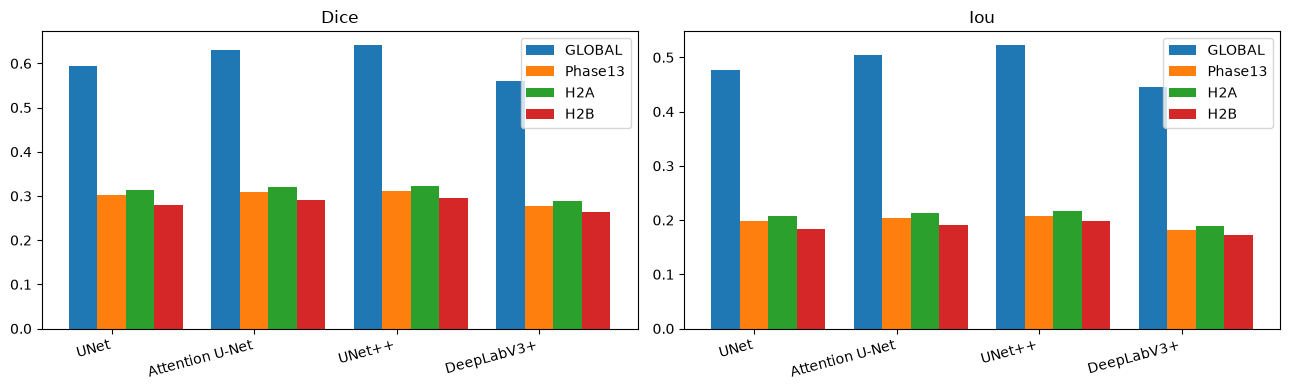

In [16]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, m in zip(axes, ["dice", "iou"]):
    x = np.arange(len(summary)); w = 0.2
    ax.bar(x - w, summary[f"global_macro_{m}"], w, label="GLOBAL")
    ax.bar(x, summary[f"phase13_predicted_macro_{m}"], w, label="Phase13")
    ax.bar(x + w, summary[f"h2a_predicted_macro_{m}"], w, label="H2A")
    ax.bar(x + 2*w, summary[f"h2b_predicted_macro_{m}"], w, label="H2B")
    ax.set_xticks(x); ax.set_xticklabels(summary["model_display"], rotation=15, ha="right")
    ax.set_title(m.capitalize()); ax.legend()
plt.tight_layout(); plt.show()


## 18. Precision / Recall

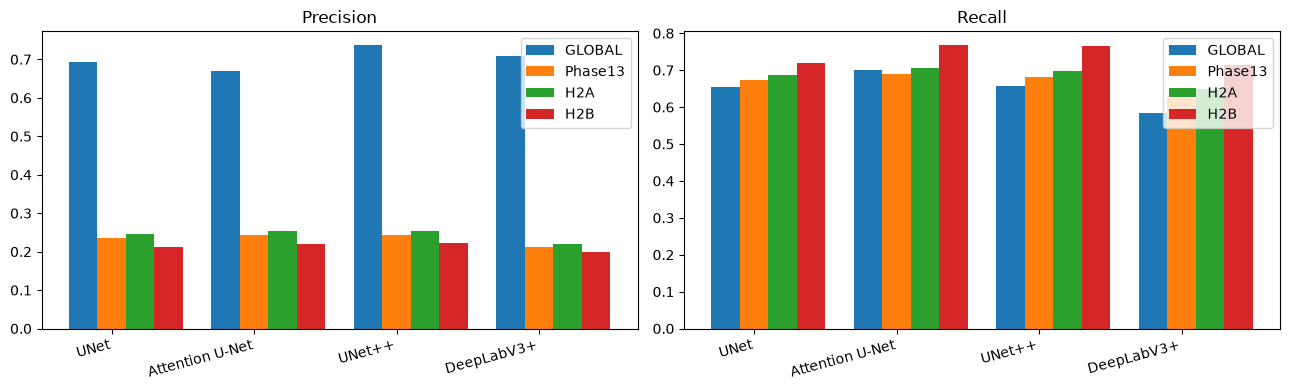

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, m in zip(axes, ["precision", "recall"]):
    x = np.arange(len(summary)); w = 0.2
    ax.bar(x - w, summary[f"global_macro_{m}"], w, label="GLOBAL")
    ax.bar(x, summary[f"phase13_predicted_macro_{m}"], w, label="Phase13")
    ax.bar(x + w, summary[f"h2a_predicted_macro_{m}"], w, label="H2A")
    ax.bar(x + 2*w, summary[f"h2b_predicted_macro_{m}"], w, label="H2B")
    ax.set_xticks(x); ax.set_xticklabels(summary["model_display"], rotation=15, ha="right")
    ax.set_title(m.capitalize()); ax.legend()
plt.tight_layout(); plt.show()


## 19. FP / FN

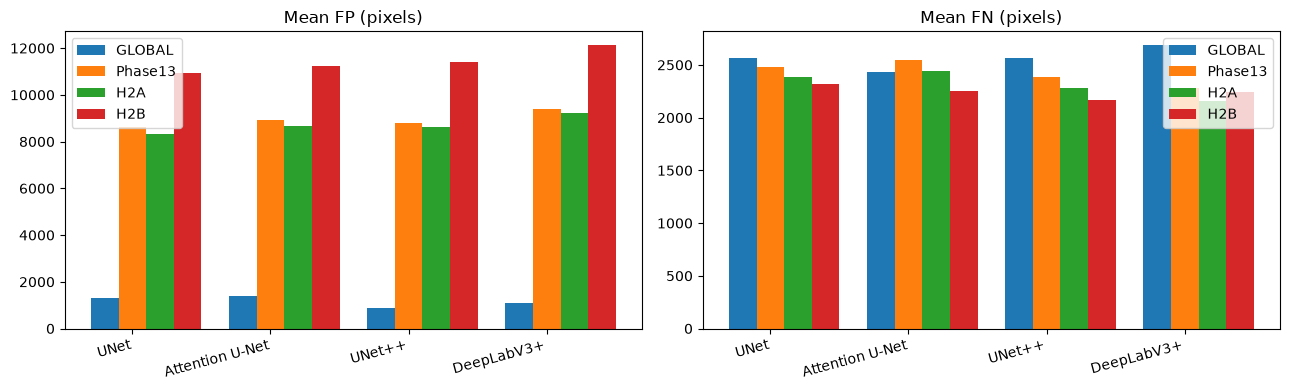

In [18]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, m in zip(axes, ["fp", "fn"]):
    x = np.arange(len(summary)); w = 0.2
    ax.bar(x - w, summary[f"mean_global_{m}"], w, label="GLOBAL")
    ax.bar(x, summary[f"mean_phase13_{m}"], w, label="Phase13")
    ax.bar(x + w, summary[f"mean_h2a_{m}"], w, label="H2A")
    ax.bar(x + 2*w, summary[f"mean_h2b_{m}"], w, label="H2B")
    ax.set_xticks(x); ax.set_xticklabels(summary["model_display"], rotation=15, ha="right")
    ax.set_title(f"Mean {m.upper()} (pixels)"); ax.legend()
plt.tight_layout(); plt.show()


## 20. Component Recoveries / Losses

In [19]:

cols = ["model_display", "component_recoveries_vs_global", "component_losses_vs_global",
        "component_recoveries_vs_phase13", "component_losses_vs_phase13",
        "component_recoveries_vs_h2a", "component_losses_vs_h2a"]
print(summary[cols].to_string(index=False))


  model_display  component_recoveries_vs_global  component_losses_vs_global  component_recoveries_vs_phase13  component_losses_vs_phase13  component_recoveries_vs_h2a  component_losses_vs_h2a
           UNet                              10                           0                                0                            6                            0                        7
Attention U-Net                               7                           0                                1                            3                            0                        4
         UNet++                              11                           0                                0                            3                            1                        4
     DeepLabV3+                              16                           0                                3                            3                            4                        4


## 21. Empty Recoveries / New Empties

In [20]:

print(summary[["model_display", "empty_recoveries", "new_empty_predictions"]].to_string(index=False))


  model_display  empty_recoveries  new_empty_predictions
           UNet                 8                      0
Attention U-Net                 3                      0
         UNet++                 5                      0
     DeepLabV3+                11                      0


## 22. Oracle-Benefit Retention

`H2B_ORACLE_BENEFIT_RETENTION = (H2B_Dice - GLOBAL_Dice) / (ORACLE_Dice - GLOBAL_Dice)`,
descriptive only. No success threshold; not redefined after seeing results.


In [21]:

print(summary[["model_display", "H2B_ORACLE_BENEFIT_RETENTION", "H2B_ORACLE_GAP"]].to_string(index=False))


  model_display  H2B_ORACLE_BENEFIT_RETENTION  H2B_ORACLE_GAP
           UNet                     -2.407893       -0.444873
Attention U-Net                     -4.860838       -0.409026
         UNet++                     -4.013603       -0.431991
     DeepLabV3+                     -1.554992       -0.485758


## 23. Size Strata

In [22]:

st = comp.groupby(["model", "size_stratum"]).agg(
    n=("native_component_id", "count"),
    global_detected=("global_detected", "sum"),
    h2b_detected=("h2b_predicted_detected", "sum"),
    h2a_detected=("h2a_predicted_detected", "sum"),
    recoveries=("GLOBAL_TO_H2B_RECOVERY", "sum"),
    losses=("GLOBAL_TO_H2B_LOSS", "sum")).reset_index()
print(st.to_string(index=False))


         model size_stratum  n  global_detected  h2b_detected  h2a_detected  recoveries  losses
attention_unet        LARGE 16               15            15            15           0       0
attention_unet       MEDIUM 36               32            34            35           2       0
attention_unet        SMALL 28               24            25            26           1       0
attention_unet         TINY 72               56            60            62           4       0
 deeplabv3plus        LARGE 16               14            15            15           1       0
 deeplabv3plus       MEDIUM 36               30            33            34           3       0
 deeplabv3plus        SMALL 28               23            26            26           3       0
 deeplabv3plus         TINY 72               47            56            55           9       0
          unet        LARGE 16               14            15            15           1       0
          unet       MEDIUM 36          

## 24. Frozen Hard-Tiny

In [23]:

ht = comp[comp["hard_tiny"]].groupby("model").agg(
    n=("native_component_id", "count"), global_detected=("global_detected", "sum"),
    h2b_detected=("h2b_predicted_detected", "sum"), h2a_detected=("h2a_predicted_detected", "sum"),
    recoveries=("GLOBAL_TO_H2B_RECOVERY", "sum"), losses=("GLOBAL_TO_H2B_LOSS", "sum"))
print(ht)


                 n  global_detected  h2b_detected  h2a_detected  recoveries  \
model                                                                         
attention_unet  15                3             6             7           3   
deeplabv3plus   15                2             5             5           3   
unet            15                0             5             6           5   
unetpp          15                0             5             5           5   

                losses  
model                   
attention_unet       0  
deeplabv3plus        0  
unet                 0  
unetpp               0  


## 25. Frozen Global-Empty

5 frozen images containing 8 native components — reported as
`GLOBAL_EMPTY_COMPONENTS_WITHIN_5_FROZEN_IMAGES`, never as "8 global-empty images".


In [24]:

ge = comp[comp["global_empty_image"]].groupby("model").agg(
    n=("native_component_id", "count"), global_detected=("global_detected", "sum"),
    h2b_detected=("h2b_predicted_detected", "sum"), h2a_detected=("h2a_predicted_detected", "sum"),
    recoveries=("GLOBAL_TO_H2B_RECOVERY", "sum"), losses=("GLOBAL_TO_H2B_LOSS", "sum"))
print("GLOBAL_EMPTY_COMPONENTS_WITHIN_5_FROZEN_IMAGES")
print(ge)


GLOBAL_EMPTY_COMPONENTS_WITHIN_5_FROZEN_IMAGES
                n  global_detected  h2b_detected  h2a_detected  recoveries  \
model                                                                        
attention_unet  8                1             4             4           3   
deeplabv3plus   8                2             3             3           1   
unet            8                0             3             3           3   
unetpp          8                0             3             3           3   

                losses  
model                   
attention_unet       0  
deeplabv3plus        0  
unet                 0  
unetpp               0  


## 26. Multi-Component

In [25]:

mc = comp[comp["multi_component_image"]].groupby("model").agg(
    n=("native_component_id", "count"), global_detected=("global_detected", "sum"),
    h2b_detected=("h2b_predicted_detected", "sum"), recoveries=("GLOBAL_TO_H2B_RECOVERY", "sum"),
    losses=("GLOBAL_TO_H2B_LOSS", "sum"))
print(mc)


                 n  global_detected  h2b_detected  recoveries  losses
model                                                                
attention_unet  98               78            85           7       0
deeplabv3plus   98               71            83          12       0
unet            98               76            83           7       0
unetpp          98               77            86           9       0


## 27. Cross-Architecture Consistency

In [26]:

print(cross.to_string(index=False))


                                    Unnamed: 0  value
             cases_h2b_improved_vs_global_all4      2
             cases_h2b_nonworse_vs_global_all4      2
                cases_h2b_worse_vs_global_all4     87
            cases_h2b_improved_vs_phase13_all4     32
               cases_h2b_worse_vs_phase13_all4     50
components_recovered_vs_global_by_at_least_one     22
        components_recovered_vs_global_by_all4      3
     components_lost_vs_global_by_at_least_one      0
             components_lost_vs_global_by_all4      0
                cases_h2b_improved_vs_h2a_all4     31
                   cases_h2b_worse_vs_h2a_all4     51


## 28. Localizer → Downstream Translation

**No monotonic causality is claimed.** This table exists only to show whether the H2B
objective-level localizer changes translate into downstream regional segmentation behaviour.


In [27]:

pd.set_option("display.max_columns", None); pd.set_option("display.width", 0)
print(link.to_string(index=False))


         model   model_display  h2b_proposal_count  h2b_pixel_any_hit_precision  h2b_bbox_any_hit_precision  h2b_tiny90  h2b_overall90  h2b_overall50  h2b_any_overlap  h2b_mean_coverage  h2b_mean_union_area  h2b_score_max  h2b_score_iqr  h2b_fraction_at_max  h2b_roc_auc  h2b_pr_auc  h2a_proposal_count  h2a_pixel_any_hit_precision  h2a_bbox_any_hit_precision  h2a_tiny90  h2a_overall90  h2a_overall50  h2a_any_overlap  h2a_mean_coverage  h2a_mean_union_area  h2a_score_max  h2a_score_iqr  h2a_fraction_at_max  h2a_roc_auc  h2a_pr_auc  phase13_proposal_count  phase13_pixel_any_hit_precision  phase13_bbox_any_hit_precision  phase13_tiny90  phase13_overall90  phase13_overall50  phase13_any_overlap  phase13_mean_coverage  phase13_mean_union_area  phase13_score_max  phase13_score_iqr  phase13_fraction_at_max  h2b_macro_dice  h2b_macro_iou  h2b_macro_precision  h2b_macro_recall  h2b_mean_fp  h2b_mean_fn  h2b_component_recoveries_vs_global  h2b_component_losses_vs_global  h2a_macro_dice  h2a_macro

## 29. Limitations

1. Single-seed adaptive VAL-development evaluation.
2. H2B is worse than H2A on every frozen localizer proposal-quality metric; the downstream
   evaluation inherits that starting point.
3. Proposal scores are fully saturated (score IQR 0.0 at the B1 best checkpoint).
4. Descriptive comparison only — no statistical superiority claim, no winner.
5. No threshold search, no proposal grid, no H1 filtering.
6. TEST remains untouched; these are development-data results only.


## 30. Adaptive VAL-Development Disclosure

H2B is adaptive VAL development undertaken after upstream regional-revision evidence. The
`SoftTargetFocalBCE(gamma=2.0)` objective was frozen **before** H2B training. The H2B best
checkpoint was frozen **before** downstream evaluation. No proposal threshold or search was
performed. No H2B result substitutes for final TEST evaluation. TEST remains untouched.


## 31. Adjudication Stop Boundary

**This notebook does NOT adjudicate H2B.**

The execution returns evidence only. H2B outcome adjudication is a separate supervisor step.

Not authorized and not performed: H2B sufficiency/partial/insufficiency declarations, winner,
optimal loss, superiority, GO/NO_GO, regional mechanism promotion, Phase14/H2C/H3 authorization,
TEST access.


## 32. Artifact SHA Registry

In [28]:

artifacts = [
    "reports/audits/post_phase13_h2b_protocol_frozen.json",
    "reports/audits/post_phase13_h2b_b1_training_evaluation.json",
    "reports/audits/post_phase13_h2b_b1_selection_replay_verification.json",
    "reports/audits/post_phase13_h2b_best_checkpoint_standalone_evaluation.json",
    "reports/audits/post_phase13_h2b_b2_downstream_integrity.json",
    "reports/tables/post_phase13_h2b_best_checkpoint_case_proposals.csv",
    "reports/tables/post_phase13_h2b_best_checkpoint_proposals.csv",
    "reports/tables/post_phase13_h2b_best_checkpoint_component_coverage.csv",
    "reports/tables/post_phase13_h2b_best_checkpoint_size_stratified.csv",
    "reports/tables/post_phase13_h2b_vs_h2a_localizer_comparison.csv",
    "reports/tables/post_phase13_h2b_downstream_case_model_metrics.csv",
    "reports/tables/post_phase13_h2b_downstream_component_model_metrics.csv",
    "reports/tables/post_phase13_h2b_downstream_model_summary.csv",
    "reports/tables/post_phase13_h2b_downstream_cross_architecture_summary.csv",
    "reports/tables/post_phase13_h2b_localizer_to_downstream_comparison.csv",
]
for a in artifacts:
    p = ROOT / a
    print(f"{sha(p) if p.exists() else 'MISSING':64s}  {Path(a).name}")


22d4e363a9375bc12828c944b1583921efa77d45b6df7d6387738d13d950949e  post_phase13_h2b_protocol_frozen.json
34a52942ea4ef9da21c4aa450a925c8c59ada771e08f99ab99c3ec669c1e2175  post_phase13_h2b_b1_training_evaluation.json
0b1e2f64d755409ff875f0ec0382f306b6d5145d3602d257ba50ce618f209c53  post_phase13_h2b_b1_selection_replay_verification.json
1d9a3032362c3099f908c0c61b84e7b1fb97b8f13552563f9ca0f670d2d0096d  post_phase13_h2b_best_checkpoint_standalone_evaluation.json
f6f128c03fdb89c3ec0efbba3850213743e0239d43a445f70a5a1ada588edb22  post_phase13_h2b_b2_downstream_integrity.json
8fa3490950d8cb2700a933fbaab73d8576950c71cb7517f6b6015fac0063fd5b  post_phase13_h2b_best_checkpoint_case_proposals.csv
9a2b200b79d511a31ecbc1087908d93cd60fc8048d895dc47d82ce2abaad699e  post_phase13_h2b_best_checkpoint_proposals.csv
8ab6724265983469d0b9c6ec390a81296c503065196f21b83a936faa52c6fa16  post_phase13_h2b_best_checkpoint_component_coverage.csv
e99ce4734037c8b9ae777ad2629843c276df4e6ff69cce2d03f10a1401029cfb  post_ph

## 33. Mandatory Complete Tables (Untruncated)

Rendered in full — no `head()`, no `tail()`, no notebook ellipsis.


In [29]:

_pd = pd
_pd.set_option("display.max_rows", None); _pd.set_option("display.max_columns", None)
_pd.set_option("display.width", 0); _pd.set_option("display.max_colwidth", None)

print("=" * 100); print(f"MODEL SUMMARY — {len(summary)} / 4 rows"); print("=" * 100)
print(summary.to_string(index=False)); print()
assert len(summary) == 4, f"model summary rows {len(summary)} != 4"


MODEL SUMMARY — 4 / 4 rows
         model   model_display  proposal_count  mean_proposals_per_image  mean_intervention_union_area  global_macro_dice  phase13_predicted_macro_dice  h2b_predicted_macro_dice  oracle_macro_dice  DELTA_H2B_GLOBAL_DICE  DELTA_H2B_PHASE13_DICE  h2a_predicted_macro_dice  h2a_predicted_macro_iou  h2a_predicted_macro_precision  h2a_predicted_macro_recall  mean_h2a_fp  mean_h2a_fn  DELTA_H2B_H2A_DICE  ORACLE_GAIN_FROM_GLOBAL  H2B_ORACLE_BENEFIT_RETENTION  H2B_ORACLE_GAP  global_macro_iou  phase13_predicted_macro_iou  h2b_predicted_macro_iou  oracle_macro_iou  global_macro_precision  phase13_predicted_macro_precision  h2b_predicted_macro_precision  oracle_macro_precision  global_macro_recall  phase13_predicted_macro_recall  h2b_predicted_macro_recall  oracle_macro_recall  mean_global_fp  mean_phase13_fp  mean_h2b_fp  mean_oracle_fp  mean_global_fn  mean_phase13_fn  mean_h2b_fn  mean_oracle_fn  fp_delta_vs_global  fp_delta_vs_phase13  fn_delta_vs_global  fn_delta_v

In [30]:

print("=" * 100); print(f"CASE-MODEL METRICS — {len(case)} / 412 rows (103 cases x 4 models)"); print("=" * 100)
print(case.to_string(index=False)); print()
assert len(case) == 412, f"case rows {len(case)} != 412"
assert case["sample_id"].nunique() == 103 and case["model"].nunique() == 4
print(f"CONFIRMED: {len(case)} rows | {case['sample_id'].nunique()} cases | {case['model'].nunique()} models")


CASE-MODEL METRICS — 412 / 412 rows (103 cases x 4 models)
                       sample_id          model   model_display  native_height  native_width  native_gt_components  h2b_proposal_count  h2b_proposal_union_area_fraction  hard_tiny_image  global_empty_image  multi_component_image  h2b_proposal_score_mean  h2b_proposal_score_max  global_dice   global_iou  global_precision  global_recall  global_tp_pixels  global_fp_pixels  global_fn_pixels  global_prediction_empty  global_hd95  global_hd95_valid global_hd95_invalid_reason  global_detected_native_components  global_missed_native_components  global_object_recall  oracle_dice  oracle_iou  oracle_precision  oracle_recall  oracle_tp_pixels  oracle_fp_pixels  oracle_fn_pixels  oracle_prediction_empty  oracle_hd95  oracle_hd95_valid  oracle_hd95_invalid_reason  oracle_detected_native_components  oracle_missed_native_components  oracle_object_recall  phase13_predicted_dice  phase13_predicted_iou  phase13_predicted_precision  phase13_pred

In [31]:

print("=" * 100); print(f"COMPONENT-MODEL METRICS — {len(comp)} / 608 rows (152 components x 4 models)"); print("=" * 100)
print(comp.to_string(index=False)); print()
assert len(comp) == 608, f"component rows {len(comp)} != 608"
print(f"CONFIRMED: {len(comp)} rows | {comp['model'].nunique()} models")


COMPONENT-MODEL METRICS — 608 / 608 rows (152 components x 4 models)
                       sample_id  native_component_id          model   model_display size_stratum  component_pixels  hard_tiny  global_empty_image  multi_component_image  h2b_coverage_fraction  h2b_covered90  h2b_covered50  h2b_any_overlap  global_detected  oracle_detected  phase13_predicted_detected  h2b_predicted_detected  GLOBAL_TO_H2B_RECOVERY  GLOBAL_TO_H2B_LOSS  PHASE13_TO_H2B_RECOVERY  PHASE13_TO_H2B_LOSS  h2a_predicted_detected  H2A_TO_H2B_RECOVERY  H2A_TO_H2B_LOSS
66b947d8ead11ae1260bc3142ca1707d                    1           unet            UNet         TINY               522      False               False                  False               0.000000          False          False            False            False             True                        True                   False                   False               False                    False                 True                    True              